In [ ]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

# 5.1


1. E(K), let's assume that we have $\lambda=\langle k\rangle$
$$
\begin{align*}
\mathbb{E}(K)
&=\sum_{k=0}^{\infty} k\,e^{-\lambda}\frac{\lambda^k}{k!}
= e^{-\lambda}\sum_{k=1}^{\infty} k\frac{\lambda^k}{k!} \\
&= e^{-\lambda}\sum_{k=1}^{\infty}\lambda\frac{\lambda^{k-1}}{(k-1)!}
= e^{-\lambda}\lambda\sum_{j=0}^{\infty}\frac{\lambda^j}{j!}
= \lambda.
\end{align*}
$$
$$
\begin{align*}
\mathbb{E}(K^2)
&=\sum_{k=0}^{\infty} k^2\,e^{-\lambda}\frac{\lambda^k}{k!}
= e^{-\lambda}\sum_{k=0}^{\infty}\big(k(k-1)+k\big)\frac{\lambda^k}{k!} \\
&= e^{-\lambda}\sum_{k=2}^{\infty}k(k-1)\frac{\lambda^k}{k!}
  + e^{-\lambda}\sum_{k=1}^{\infty}k\frac{\lambda^k}{k!} \\
&= e^{-\lambda}\lambda^2\sum_{m=0}^{\infty}\frac{\lambda^m}{m!} + \lambda
= \lambda^2 + \lambda.
\end{align*}
$$
$$
\operatorname{Var}(K)=\mathbb{E}(K^2)-[\mathbb{E}(K)]^2
= (\lambda^2+\lambda)-\lambda^2 = \lambda.
$$
We can see that $\frac{k\lambda^k}{k!} = \frac{\lambda* k * \lambda^{k-1}}{k (k-1)!}$ 
$= \lambda \frac{\lambda^{k-1}}{(k - 1)!}$

# 5.2

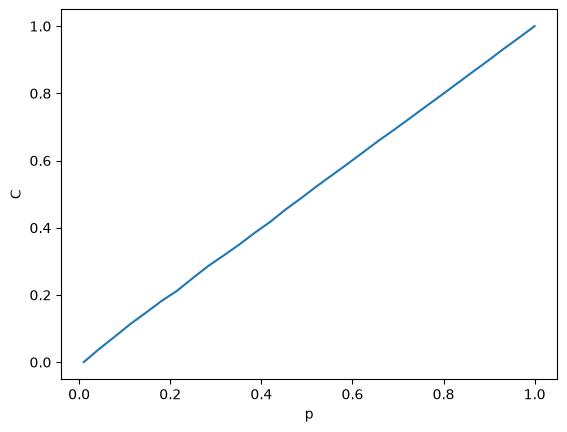

In [1]:
p = np.linspace(0.01, 1, 30)
c = [np.mean([nx.average_clustering(nx.gnp_random_graph(100, x))
              for _ in range(20)]) for x in p]

plt.plot(p, c)
plt.xlabel("p")
plt.ylabel("C")
plt.show()

# 5.3

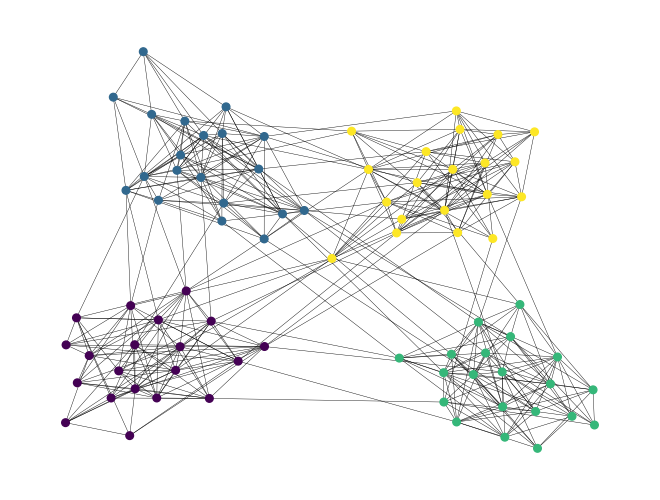

In [5]:
p_in, p_out = 0.5, 0.02
p = [[p_in if i == j else p_out for j in range(4)] for i in range(4)]
G = nx.stochastic_block_model([20] * 4, p)

nx.draw(G, node_color=[i // 20 for i in G], node_size=30, width=0.3)
plt.show()

# 5.4

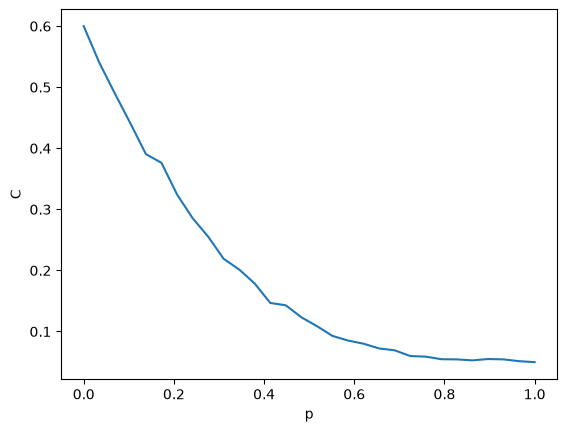

In [8]:
import numpy as np
import matplotlib.pyplot as plt

def watts_strogatz(n, k, p):
    assert 0 < k < n and k % 2 == 0 and 0 <= p <= 1

    G = []
    for u in range(n):
        G.append(set())

    edges = []
    for u in range(n):
        for distance in range(1, k // 2 + 1):
            v = (u + distance) % n
            edges.append((u, v))
            G[u].add(v)
            G[v].add(u)

    for u, v in edges:
        if np.random.random() < p:
            candidates = []
            for w in range(n):
                if w != u and w not in G[u]:
                    candidates.append(w)

            if candidates:
                w = int(np.random.choice(candidates))
                G[u].remove(v)
                G[v].remove(u)
                G[u].add(w)
                G[w].add(u)

    return G

def clustering(G):
    values = []
    for u in range(len(G)):
        neighbors = list(G[u])
        degree = len(neighbors)
        links = 0

        for i in range(degree):
            for j in range(i + 1, degree):
                if neighbors[j] in G[neighbors[i]]:
                    links += 1

        if degree > 1:
            values.append(2 * links / (degree * (degree - 1)))
        else:
            values.append(0)

    return np.mean(values)

p = np.linspace(0, 1, 30)
c = []
for x in p:
    results = []
    for _ in range(20):
        G = watts_strogatz(100, 6, x)
        results.append(clustering(G))
    c.append(np.mean(results))

plt.plot(p, c)
plt.xlabel("p")
plt.ylabel("C")
plt.show()